# LAB05 - Mineral Prospectivity Mapping

Executed public walkthrough of the validated synthetic LAB05 workflow.

This notebook reads frozen result artifacts rather than retraining the experiment.
The visual system uses an original editorial/newsroom style: white background,
restrained grids, grayscale structure, and a compact accent palette.

## Scientific design

LAB05 uses spatial validation, out-of-fold evaluation, out-of-sample ranking,
and a sealed hidden-oracle evaluation.

Prospectivity scores are ranking scores, not calibrated probabilities.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter, MaxNLocator

%matplotlib inline

LAB_DIR = Path.cwd()
if LAB_DIR.name != "lab05_mineral_prospectivity":
    candidate = Path("labs/lab05_mineral_prospectivity")
    if candidate.exists():
        LAB_DIR = candidate.resolve()

RESULTS_DIR = LAB_DIR / "results"
README_PATH = LAB_DIR / "README.md"

assert RESULTS_DIR.exists(), RESULTS_DIR
assert README_PATH.exists(), README_PATH

readme = README_PATH.read_text(encoding="utf-8")

plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.facecolor": "white",
        "axes.edgecolor": "#b8b8b8",
        "axes.linewidth": 0.8,
        "axes.grid": True,
        "grid.color": "#dddddd",
        "grid.linewidth": 0.8,
        "grid.alpha": 0.55,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 11,
        "axes.titlesize": 15,
        "axes.titleweight": "bold",
        "legend.frameon": False,
    }
)

INK = "#222222"
MUTED = "#6f6f6f"
ACCENT = "#b32025"
STEEL = "#596b75"

FEATURE_COLORS = {
    "A": "#2F5D7E",
    "B": "#C07A3D",
    "C": "#4F7C72",
}

MODEL_MARKERS = {
    "dummy": "X",
    "logistic regression": "o",
    "random forest": "s",
    "ridge": "D",
    "gradient boosting": "^",
    "xgboost": "P",
}

FALLBACK_MARKERS = ["D", "^", "v", "P", "*", "<", ">"]

def load_csv(name):
    path = RESULTS_DIR / name
    assert path.exists(), path
    return pd.read_csv(path)

def find_column(df, exact=(), contains=(), required=True):
    lower = {c.lower(): c for c in df.columns}

    for item in exact:
        if item.lower() in lower:
            return lower[item.lower()]

    for column in df.columns:
        low = column.lower()
        if all(token.lower() in low for token in contains):
            return column

    if required:
        raise AssertionError(
            f"Could not resolve column. exact={exact}, "
            f"contains={contains}, available={list(df.columns)}"
        )

    return None

def normalize_model_name(value):
    return (
        str(value)
        .replace("_", " ")
        .replace("-", " ")
        .strip()
        .lower()
    )

def pct_axis(ax, axis, values):
    values = np.asarray(values, dtype=float)

    if (
        values.size
        and np.isfinite(values).any()
        and np.nanmax(values) <= 1.0000001
    ):
        if axis == "x":
            ax.xaxis.set_major_formatter(PercentFormatter(1.0))
        else:
            ax.yaxis.set_major_formatter(PercentFormatter(1.0))

print("LAB05_ARTIFACT_LAYER = READY")

LAB05_ARTIFACT_LAYER = READY


In [2]:
benchmark = load_csv("benchmark_oof_aggregate_metrics.csv")
ranking_summary = load_csv("prospectivity_ranking_summary_oos.csv")
success_curve = load_csv("success_rate_curve_oof.csv")
scores = load_csv("prospectivity_scores_oos.csv")
hidden_ranks = load_csv("oracle_hidden_deposit_ranks.csv")

print("benchmark:", benchmark.shape)
print("ranking_summary:", ranking_summary.shape)
print("success_curve:", success_curve.shape)
print("scores:", scores.shape)
print("hidden_ranks:", hidden_ranks.shape)

benchmark: (18, 10)
ranking_summary: (3, 6)
success_curve: (1080, 9)
scores: (6400, 21)
hidden_ranks: (115, 9)


## 1. Spatial benchmark

The validated public milestone selected **Feature A + Logistic Regression**
using mean pooled out-of-fold Average Precision under spatial validation.

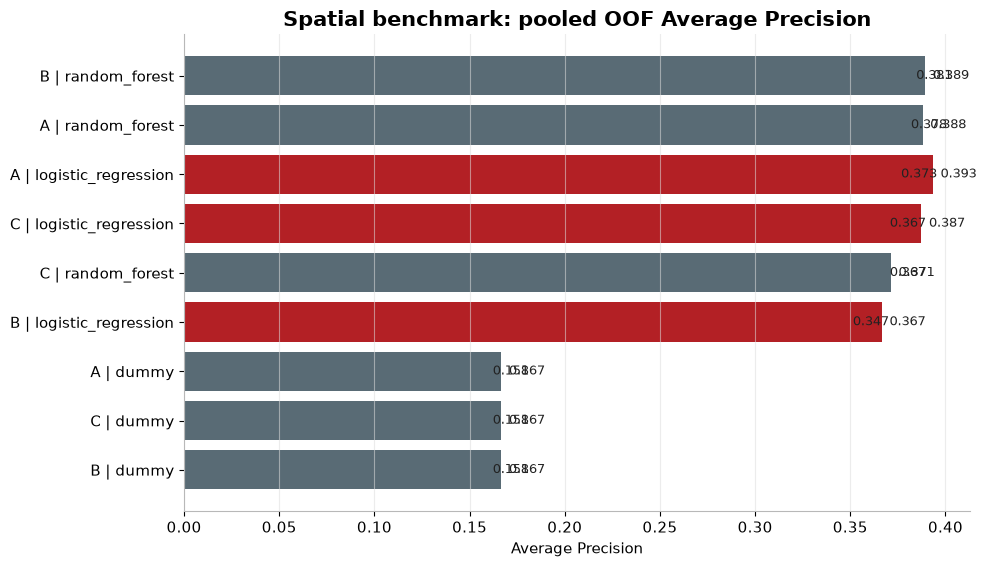

In [3]:
feature_col = find_column(
    benchmark,
    exact=(
        "feature_set",
        "feature_family",
        "feature_configuration",
        "evidence_configuration",
    ),
    contains=("feature",),
    required=False,
)

model_col = find_column(
    benchmark,
    exact=("model", "model_name", "estimator"),
    contains=("model",),
    required=False,
)

ap_col = find_column(
    benchmark,
    exact=(
        "mean_pooled_oof_average_precision",
        "mean_average_precision",
        "average_precision_mean",
        "mean_ap",
    ),
    contains=("average", "precision"),
)

plot_df = benchmark.copy()

if feature_col and model_col:
    plot_df["label"] = (
        plot_df[feature_col].astype(str)
        + " | "
        + plot_df[model_col].astype(str)
    )
elif model_col:
    plot_df["label"] = plot_df[model_col].astype(str)
elif feature_col:
    plot_df["label"] = plot_df[feature_col].astype(str)
else:
    plot_df["label"] = [
        f"Configuration {i + 1}"
        for i in range(len(plot_df))
    ]

plot_df = plot_df.sort_values(ap_col, ascending=True)

fig, ax = plt.subplots(figsize=(10, 5.8))

colors = [
    ACCENT if "logistic" in label.lower() else STEEL
    for label in plot_df["label"]
]

bars = ax.barh(
    plot_df["label"],
    plot_df[ap_col],
    color=colors,
    edgecolor="none",
)

ax.set_title("Spatial benchmark: pooled OOF Average Precision")
ax.set_xlabel("Average Precision")
ax.set_ylabel("")
ax.grid(axis="y", visible=False)

for bar, value in zip(bars, plot_df[ap_col]):
    ax.text(
        float(value) + 0.004,
        bar.get_y() + bar.get_height() / 2,
        f"{float(value):.3f}",
        va="center",
        fontsize=9,
        color=INK,
    )

plt.tight_layout()
plt.show()

## 2. ROC-AUC vs Average Precision

This plot compares discrimination and positive-class ranking quality without
changing the frozen model-selection rule.

To keep the dense upper-right cluster readable:

- **color encodes the feature set**;
- **marker shape encodes the model family**;
- labels are moved to external legends;
- only the frozen selected model receives a direct annotation.

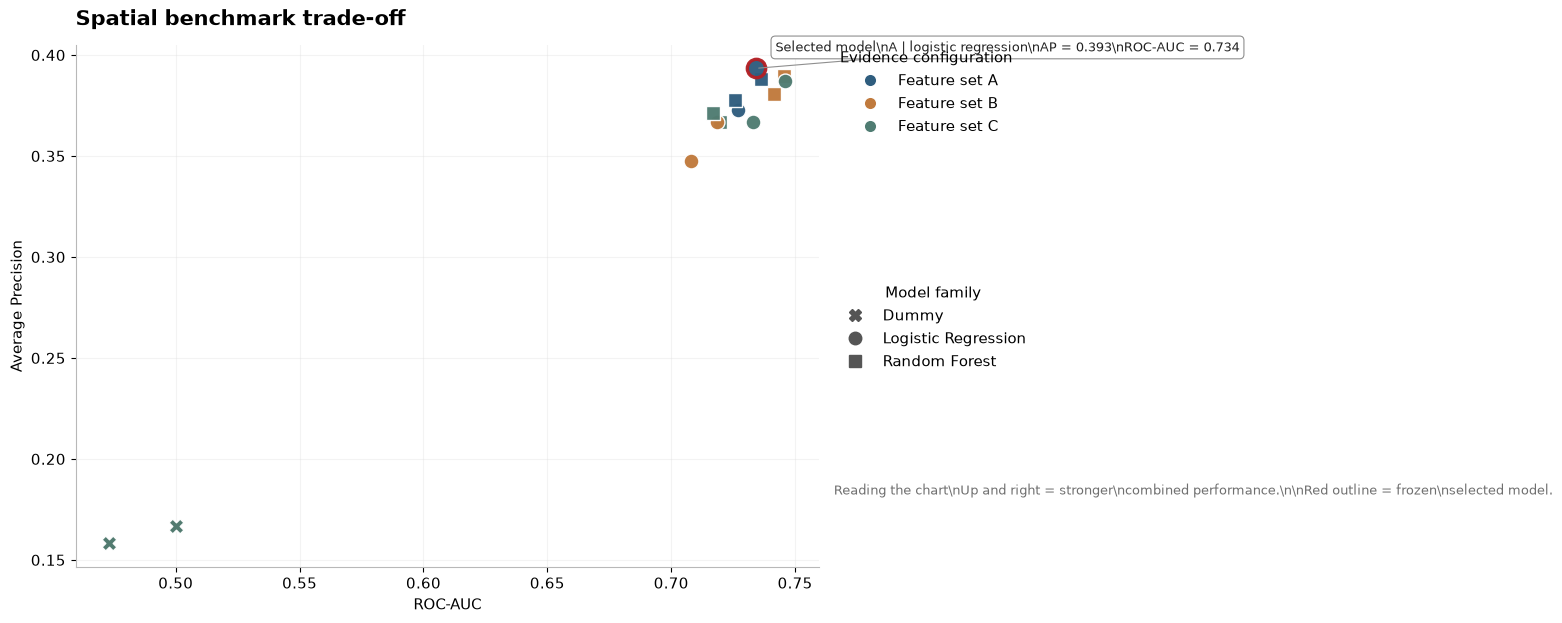

In [4]:
roc_col = find_column(
    benchmark,
    exact=(
        "mean_spatial_roc_auc",
        "mean_roc_auc",
        "roc_auc_mean",
        "mean_auc",
    ),
    contains=("roc", "auc"),
    required=False,
)

if roc_col is not None and feature_col is not None and model_col is not None:
    tradeoff = benchmark[
        [feature_col, model_col, roc_col, ap_col]
    ].copy()

    tradeoff["feature_set"] = (
        tradeoff[feature_col]
        .astype(str)
        .str.strip()
    )

    tradeoff["model_name"] = (
        tradeoff[model_col]
        .map(normalize_model_name)
    )

    feature_levels = list(
        dict.fromkeys(tradeoff["feature_set"].tolist())
    )

    model_levels = list(
        dict.fromkeys(tradeoff["model_name"].tolist())
    )

    feature_palette = FEATURE_COLORS.copy()

    fallback_feature_colors = [
        "#7C8B95",
        "#8A6F8F",
        "#8A7A55",
        "#5F748A",
    ]

    for index, feature in enumerate(feature_levels):
        if feature not in feature_palette:
            feature_palette[feature] = fallback_feature_colors[
                index % len(fallback_feature_colors)
            ]

    marker_map = MODEL_MARKERS.copy()

    unknown_models = [
        model
        for model in model_levels
        if model not in marker_map
    ]

    for index, model in enumerate(unknown_models):
        marker_map[model] = FALLBACK_MARKERS[
            index % len(FALLBACK_MARKERS)
        ]

    selected_mask = (
        tradeoff["feature_set"].eq("A")
        & tradeoff["model_name"].eq("logistic regression")
    )

    if selected_mask.sum() == 1:
        selected_index = tradeoff.index[selected_mask][0]
    else:
        selected_index = tradeoff[ap_col].idxmax()

    fig, ax = plt.subplots(figsize=(11.8, 6.7))

    for index, row in tradeoff.iterrows():
        is_selected = index == selected_index

        ax.scatter(
            row[roc_col],
            row[ap_col],
            s=175 if is_selected else 115,
            marker=marker_map[row["model_name"]],
            color=feature_palette[row["feature_set"]],
            edgecolor=ACCENT if is_selected else "white",
            linewidth=2.4 if is_selected else 1.0,
            alpha=0.97,
            zorder=4 if is_selected else 3,
        )

    selected = tradeoff.loc[selected_index]

    ax.annotate(
        (
            "Selected model\\n"
            f"{selected['feature_set']} | "
            f"{selected['model_name']}\\n"
            f"AP = {float(selected[ap_col]):.3f}\\n"
            f"ROC-AUC = {float(selected[roc_col]):.3f}"
        ),
        xy=(
            selected[roc_col],
            selected[ap_col],
        ),
        xytext=(14, 10),
        textcoords="offset points",
        ha="left",
        va="bottom",
        fontsize=9,
        color=INK,
        bbox={
            "boxstyle": "round,pad=0.35",
            "facecolor": "white",
            "edgecolor": "#8f8f8f",
            "linewidth": 0.8,
        },
        arrowprops={
            "arrowstyle": "-",
            "color": "#8f8f8f",
            "linewidth": 0.8,
        },
        zorder=5,
    )

    ax.set_title(
        "Spatial benchmark trade-off",
        loc="left",
        pad=14,
    )

    ax.set_xlabel("ROC-AUC")
    ax.set_ylabel("Average Precision")
    ax.grid(True, linewidth=0.8, alpha=0.35)

    feature_handles = [
        Line2D(
            [0],
            [0],
            marker="o",
            linestyle="",
            markersize=9,
            markerfacecolor=feature_palette[feature],
            markeredgecolor="white",
            markeredgewidth=1.0,
            label=f"Feature set {feature}",
        )
        for feature in feature_levels
    ]

    model_handles = [
        Line2D(
            [0],
            [0],
            marker=marker_map[model],
            linestyle="",
            markersize=9,
            markerfacecolor="#555555",
            markeredgecolor="#555555",
            color="#555555",
            label=model.title(),
        )
        for model in model_levels
    ]

    feature_legend = ax.legend(
        handles=feature_handles,
        title="Evidence configuration",
        loc="upper left",
        bbox_to_anchor=(1.02, 1.00),
        borderaxespad=0.0,
        frameon=False,
    )

    ax.add_artist(feature_legend)

    ax.legend(
        handles=model_handles,
        title="Model family",
        loc="upper left",
        bbox_to_anchor=(1.02, 0.55),
        borderaxespad=0.0,
        frameon=False,
    )

    ax.text(
        1.02,
        0.16,
        (
            "Reading the chart\\n"
            "Up and right = stronger\\n"
            "combined performance.\\n\\n"
            "Red outline = frozen\\n"
            "selected model."
        ),
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=9,
        color=MUTED,
    )

    fig.subplots_adjust(
        left=0.09,
        right=0.72,
        bottom=0.12,
        top=0.90,
    )

    plt.show()

else:
    print("ROC_AUC_PLOT = SKIPPED_REQUIRED_COLUMNS_NOT_FOUND")

## 3. Out-of-sample prospectivity ranking

Candidate cells are ranked using out-of-sample prospectivity scores.

The score is not interpreted as a calibrated probability.

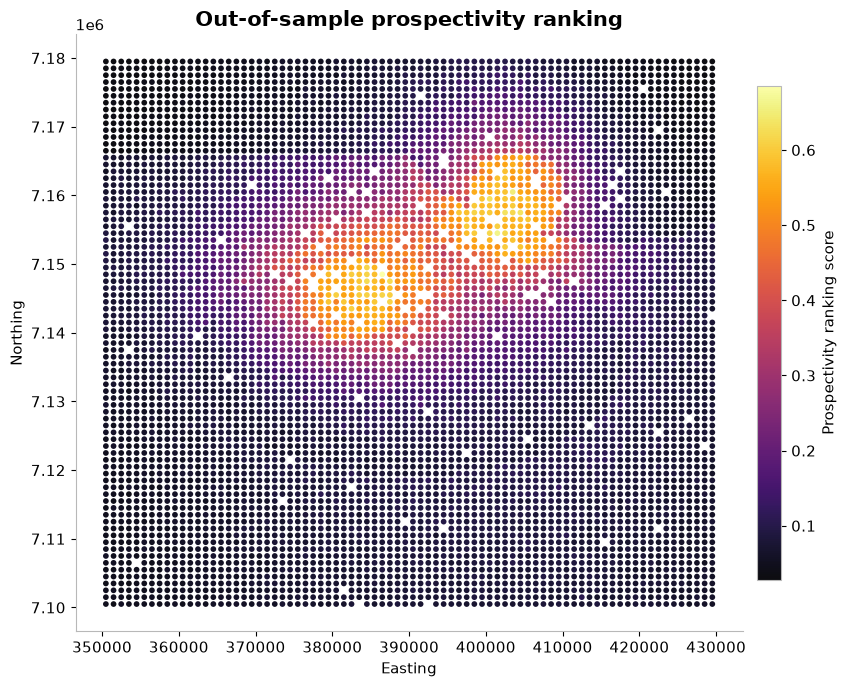

In [5]:
x_col = find_column(
    scores,
    exact=("x", "easting", "x_coord", "centroid_x", "x_m"),
    contains=("east",),
    required=False,
)

if x_col is None:
    x_col = find_column(
        scores,
        contains=("x",),
        required=False,
    )

y_col = find_column(
    scores,
    exact=("y", "northing", "y_coord", "centroid_y", "y_m"),
    contains=("north",),
    required=False,
)

if y_col is None:
    y_col = find_column(
        scores,
        contains=("y",),
        required=False,
    )

score_col = find_column(
    scores,
    exact=(
        "prospectivity_score",
        "mean_oos_score",
        "oos_score",
        "score",
    ),
    contains=("prospectivity", "score"),
    required=False,
)

if score_col is None:
    score_col = find_column(
        scores,
        contains=("score",),
        required=True,
    )

assert x_col is not None and y_col is not None, list(scores.columns)

spatial = scores[
    [x_col, y_col, score_col]
].dropna()

fig, ax = plt.subplots(figsize=(8.6, 7.0))

scatter = ax.scatter(
    spatial[x_col],
    spatial[y_col],
    c=spatial[score_col],
    cmap="inferno",
    s=17,
    linewidths=0,
    alpha=0.95,
)

ax.set_title("Out-of-sample prospectivity ranking")
ax.set_xlabel(x_col)
ax.set_ylabel(y_col)
ax.grid(False)

cbar = fig.colorbar(
    scatter,
    ax=ax,
    fraction=0.035,
    pad=0.02,
)

cbar.set_label("Prospectivity ranking score")

plt.tight_layout()
plt.show()

## 4. Success-rate curve

The diagonal represents random prioritization.

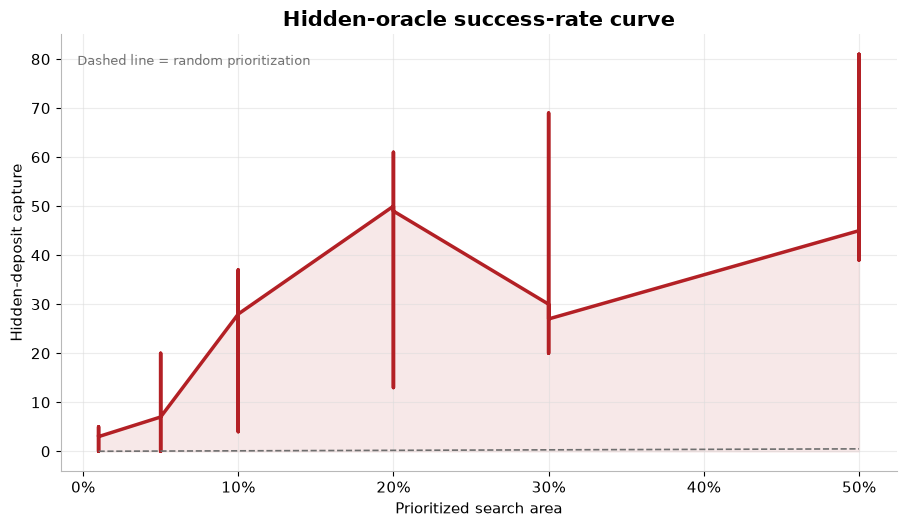

In [6]:
curve_x = find_column(
    success_curve,
    exact=(
        "prioritized_area_fraction",
        "area_fraction",
        "candidate_fraction",
        "fraction_examined",
        "search_fraction",
    ),
    contains=("fraction",),
    required=False,
)

curve_y = find_column(
    success_curve,
    exact=(
        "hidden_capture_rate",
        "capture_rate",
        "success_rate",
        "recall",
    ),
    contains=("capture",),
    required=False,
)

if curve_x is None:
    curve_x = find_column(
        success_curve,
        contains=("area",),
        required=True,
    )

if curve_y is None:
    curve_y = find_column(
        success_curve,
        contains=("rate",),
        required=True,
    )

curve = (
    success_curve[
        [curve_x, curve_y]
    ]
    .dropna()
    .sort_values(curve_x)
)

fig, ax = plt.subplots(figsize=(9.2, 5.4))

ax.plot(
    curve[curve_x],
    curve[curve_y],
    color=ACCENT,
    linewidth=2.5,
)

ax.fill_between(
    curve[curve_x],
    curve[curve_y],
    color=ACCENT,
    alpha=0.10,
)

ax.plot(
    curve[curve_x],
    curve[curve_x],
    color=MUTED,
    linewidth=1.2,
    linestyle="--",
)

ax.set_title("Hidden-oracle success-rate curve")
ax.set_xlabel("Prioritized search area")
ax.set_ylabel("Hidden-deposit capture")

pct_axis(
    ax,
    "x",
    curve[curve_x],
)

pct_axis(
    ax,
    "y",
    curve[curve_y],
)

ax.text(
    0.02,
    0.93,
    "Dashed line = random prioritization",
    transform=ax.transAxes,
    fontsize=9,
    color=MUTED,
)

plt.tight_layout()
plt.show()

## 5. Hidden-deposit rank distribution

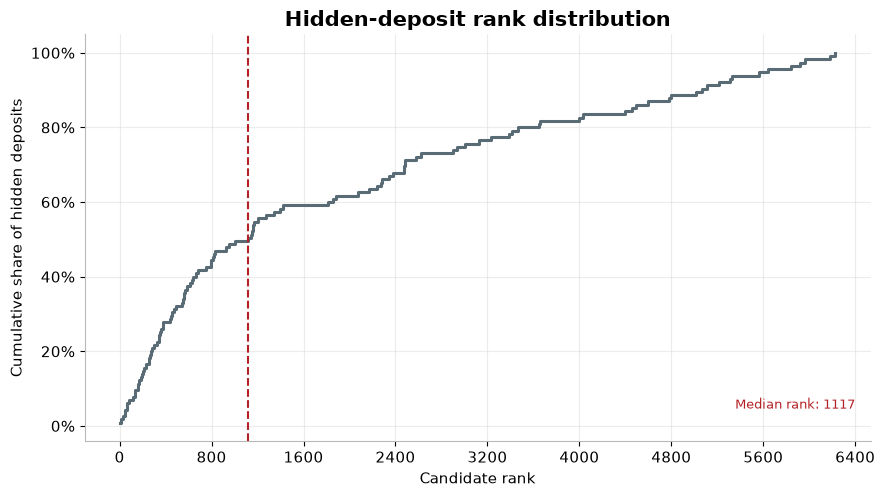

In [7]:
rank_col = find_column(
    hidden_ranks,
    exact=(
        "rank",
        "candidate_rank",
        "hidden_deposit_rank",
        "prospectivity_rank",
    ),
    contains=("rank",),
    required=False,
)

if rank_col is not None:
    ranks = (
        hidden_ranks[rank_col]
        .dropna()
        .astype(float)
        .sort_values()
        .to_numpy()
    )

    y = (
        np.arange(1, len(ranks) + 1)
        / len(ranks)
    )

    fig, ax = plt.subplots(figsize=(9.0, 5.1))

    ax.step(
        ranks,
        y,
        where="post",
        color=STEEL,
        linewidth=2.2,
    )

    ax.axvline(
        np.median(ranks),
        color=ACCENT,
        linewidth=1.5,
        linestyle="--",
    )

    ax.set_title("Hidden-deposit rank distribution")
    ax.set_xlabel("Candidate rank")
    ax.set_ylabel("Cumulative share of hidden deposits")

    pct_axis(
        ax,
        "y",
        y,
    )

    ax.xaxis.set_major_locator(
        MaxNLocator(integer=True)
    )

    ax.text(
        0.98,
        0.08,
        f"Median rank: {np.median(ranks):.0f}",
        transform=ax.transAxes,
        ha="right",
        color=ACCENT,
        fontsize=9.5,
    )

    plt.tight_layout()
    plt.show()

else:
    print("HIDDEN_RANK_PLOT = SKIPPED_COLUMN_NOT_FOUND")

## Frozen public reference metrics

Hidden-oracle AP `0.056650`, ROC-AUC `0.709070`, and lifts `5.22x`,
`4.35x`, and `3.83x` remain the frozen public reference values.

In [8]:
expected = [
    "0.056650",
    "0.709070",
    "5.22x",
    "4.35x",
    "3.83x",
]

for value in expected:
    assert value in readme, (
        f"Validated README missing frozen metric: {value}"
    )

print("FROZEN_PUBLIC_METRICS = PASS")

FROZEN_PUBLIC_METRICS = PASS


## Interpretation

LAB05 demonstrates a reproducible spatial prioritization workflow rather than
a calibrated deposit-probability engine.

Its portfolio value is the combination of spatial validation, leakage controls,
model freeze, out-of-sample ranking, hidden-oracle evaluation, automated QA,
and explicit limitations.